# Data
* train.csv - Personal records for about two-thirds (~8700) of the passengers, to be used as training data.
* PassengerId - A unique Id for each passenger. Each Id takes the form gggg_pp where gggg indicates a group the passenger is travelling with and pp is their number within the group. People in a group are often family members, but not always.
* HomePlanet - The planet the passenger departed from, typically their planet of permanent residence.
* CryoSleep - Indicates whether the passenger elected to be put into suspended animation for the duration of the voyage. Passengers in cryosleep are confined to their cabins.
* Cabin - The cabin number where the passenger is staying. Takes the form deck/num/side, where side can be either P for Port or S for Starboard.
* Destination - The planet the passenger will be debarking to.
* Age - The age of the passenger.
* VIP - Whether the passenger has paid for special VIP service during the voyage.
* RoomService, FoodCourt, ShoppingMall, Spa, VRDeck - Amount the passenger has billed at each of the Spaceship Titanic's many luxury amenities.
* Name - The first and last names of the passenger.
* Transported - Whether the passenger was transported to another dimension. This is the target, the column you are trying to predict.
# test.csv
Personal records for the remaining one-third (~4300) of the passengers, to be used as test data. Your task is to predict the value of Transported for the passengers in this set.

In [16]:
from autogluon.tabular import TabularDataset, TabularPredictor
from autogluon.features.generators import AutoMLPipelineFeatureGenerator
from fastcore.basics import true

In [17]:
import pandas as pd

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample_submission = pd.read_csv('sample_submission.csv')

train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [18]:
# Simpan Kolum ID nya
PassengerId_train = train['PassengerId']
PassengerId_test = test['PassengerId']

#Drop kolom IDnya
train = train.drop(['PassengerId'], axis=1)
test = test.drop(['PassengerId'], axis=1)

In [19]:
print('------Data Train -------')
print(train.describe())
print('------Data Test -------')
print(test.describe())

------Data Train -------
               Age   RoomService     FoodCourt  ShoppingMall           Spa  \
count  8514.000000   8512.000000   8510.000000   8485.000000   8510.000000   
mean     28.827930    224.687617    458.077203    173.729169    311.138778   
std      14.489021    666.717663   1611.489240    604.696458   1136.705535   
min       0.000000      0.000000      0.000000      0.000000      0.000000   
25%      19.000000      0.000000      0.000000      0.000000      0.000000   
50%      27.000000      0.000000      0.000000      0.000000      0.000000   
75%      38.000000     47.000000     76.000000     27.000000     59.000000   
max      79.000000  14327.000000  29813.000000  23492.000000  22408.000000   

             VRDeck  
count   8505.000000  
mean     304.854791  
std     1145.717189  
min        0.000000  
25%        0.000000  
50%        0.000000  
75%       46.000000  
max    24133.000000  
------Data Test -------
               Age   RoomService     FoodCourt  Sh

In [20]:
print('------Data Train -------')
print(train.info())
print('------Data Test -------')
print(test.info())

------Data Train -------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HomePlanet    8492 non-null   object 
 1   CryoSleep     8476 non-null   object 
 2   Cabin         8494 non-null   object 
 3   Destination   8511 non-null   object 
 4   Age           8514 non-null   float64
 5   VIP           8490 non-null   object 
 6   RoomService   8512 non-null   float64
 7   FoodCourt     8510 non-null   float64
 8   ShoppingMall  8485 non-null   float64
 9   Spa           8510 non-null   float64
 10  VRDeck        8505 non-null   float64
 11  Name          8493 non-null   object 
 12  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(6)
memory usage: 823.6+ KB
None
------Data Test -------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 12 columns):
 #   Column        Non-N

In [21]:
# Menggunakan modus bawaan pandas
label_col = ['HomePlanet', 'CryoSleep', 'Cabin', 'Destination']

nomina_col = ['Age', 'ShoppingMall', 'Spa', 'FoodCourt', 'RoomService']

for col in label_col:
    modus_col = train[col].mode()[0]

    train[col] = train[col].fillna(modus_col)
    test[col] = test[col].fillna(modus_col)


train.isnull().sum()
test.isnull().sum()

C:\Users\hajar\AppData\Local\Temp\ipykernel_39208\2435335991.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train[col] = train[col].fillna(modus_col)
C:\Users\hajar\AppData\Local\Temp\ipykernel_39208\2435335991.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test[col] = test[col].fillna(modus_col)


HomePlanet        0
CryoSleep         0
Cabin             0
Destination       0
Age              91
VIP              93
RoomService      82
FoodCourt       106
ShoppingMall     98
Spa             101
VRDeck           80
Name             94
dtype: int64

In [22]:
median_age = train['Age'].median()
train['Age'] = train['Age'].fillna(median_age)
test['Age'] = test['Age'].fillna(median_age)

In [23]:
import numpy as np

# Hitung median usia
median_age = train['Age'].median()

# Tentukan nilai pengganti (True jika age > median, False jika tidak)
nilai_pengganti_train = np.where(train['Age'] > median_age, True, False)
nilai_pengganti_test = np.where(test['Age'] > median_age, True, False)

# Isi kolom vip yang NaN saja dengan nilai pengganti di atas
train['VIP'] = train['VIP'].fillna(pd.Series(nilai_pengganti_train, index=train.index))
test['VIP'] = test['VIP'].fillna(pd.Series(nilai_pengganti_test, index=test.index))


C:\Users\hajar\AppData\Local\Temp\ipykernel_39208\4195429421.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train['VIP'] = train['VIP'].fillna(pd.Series(nilai_pengganti_train, index=train.index))
C:\Users\hajar\AppData\Local\Temp\ipykernel_39208\4195429421.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test['VIP'] = test['VIP'].fillna(pd.Series(nilai_pengganti_test, index=test.index))


In [24]:
modus_room = train['RoomService'].mode()[0]

train['RoomService'] = train['RoomService'].fillna(modus_room)
test['RoomService'] = test['RoomService'].fillna(modus_room)

In [25]:
train[['VIP', 'RoomService', 'Age']]

,VIP,RoomService,Age
0,False,0.0,39.0
1,False,109.0,24.0
2,True,43.0,58.0
3,False,0.0,33.0
4,False,303.0,16.0
...,...,...,...
8688,True,0.0,41.0
8689,False,0.0,18.0
8690,False,0.0,26.0
8691,False,0.0,32.0


In [26]:
#train.duplicated().sum()
test.duplicated().sum()

np.int64(0)

In [27]:
# Hitung Kuartil 1 (25%) dan Kuartil 3 (75%)
Q1 = train['Age'].quantile(0.25)
Q3 = train['Age'].quantile(0.75)

# Hitung selisih rentang kuartil
IQR = Q3 - Q1

# Tentukan ambang batas bawah dan atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Tampilkan baris data yang merupakan outlier
outlier_data = train[(train['Age'] < batas_bawah) | (train['Age'] > batas_atas)]
outlier_data['Age']


109     64.0
118     67.0
248     63.0
280     67.0
335     63.0
        ... 
8254    64.0
8288    76.0
8369    73.0
8516    70.0
8539    64.0
Name: Age, Length: 162, dtype: float64

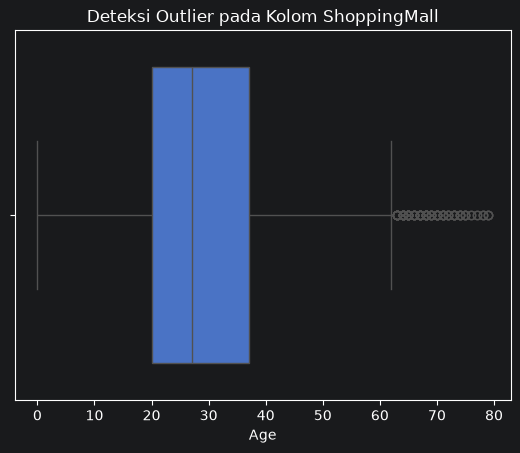

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat boxplot untuk kolom age
sns.boxplot(x=train['Age'])
plt.title('Deteksi Outlier pada Kolom ShoppingMall')
plt.show()


KeyError: 'ShoppingMall'

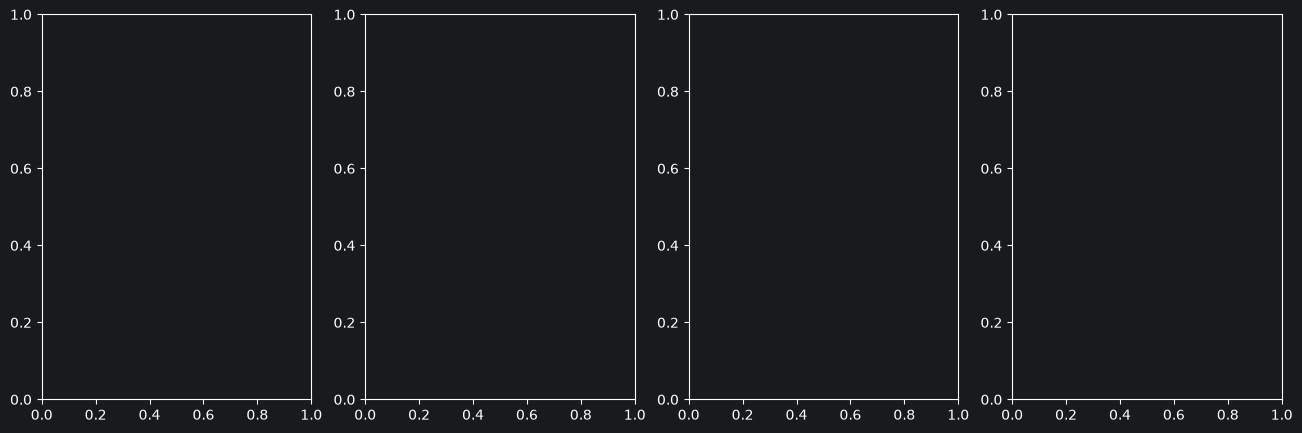

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

kolom_target = ['ShoppingMall', 'FoodCourt', 'Spa', 'VRDeck']
jml_kolom = len(kolom_target)

# Membuat grid subplots (1 baris, N kolom)
fig, axes = plt.subplots(1, jml_kolom, figsize=(4 * jml_kolom, 5))

# Looping untuk mengisi tiap grid dengan boxplot masing-masing
for i, col in enumerate(kolom_target):
    sns.boxplot(y=train[col], ax=axes[i])
    axes[i].set_title(f'Outlier {col}')
    axes[i].set_ylabel('')  # Menghapus label Y agar rapi

plt.tight_layout()
plt.show()



In [42]:
# Penanganan Outliers - buat kolom baru untuk mendapatkan log dari

for col in kolom_target:
    train[f'{col}_log'] = np.log1p(train[col])
    test[f'{col}_log'] = np.log1p(test[col])

    train.drop(columns=[col], inplace=True)
    test.drop(columns=[col], inplace=True )



In [43]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   HomePlanet        8693 non-null   object 
 1   CryoSleep         8693 non-null   bool   
 2   Cabin             8693 non-null   object 
 3   Destination       8693 non-null   object 
 4   Age               8693 non-null   float64
 5   VIP               8693 non-null   bool   
 6   RoomService       8693 non-null   float64
 7   Name              8493 non-null   object 
 8   Transported       8693 non-null   bool   
 9   ShoppingMall_log  8485 non-null   float64
 10  FoodCourt_log     8510 non-null   float64
 11  Spa_log           8510 non-null   float64
 12  VRDeck_log        8505 non-null   float64
dtypes: bool(3), float64(6), object(4)
memory usage: 704.7+ KB


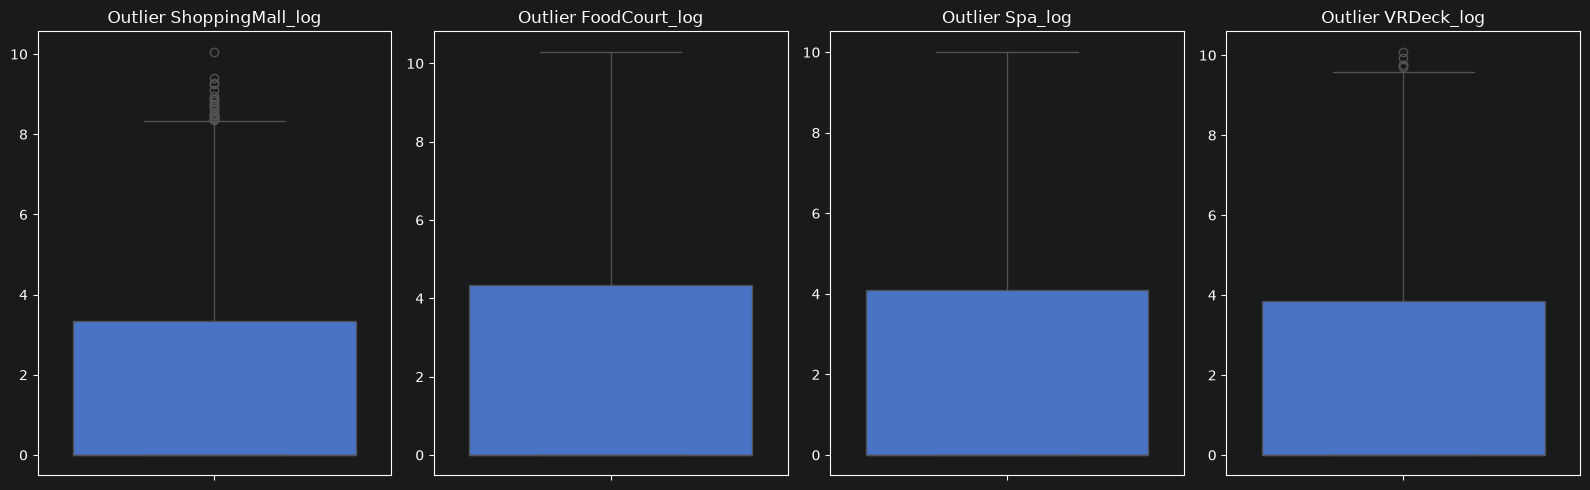

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

kolom_target = ['ShoppingMall_log', 'FoodCourt_log', 'Spa_log', 'VRDeck_log']
jml_kolom = len(kolom_target)

# Membuat grid subplots (1 baris, N kolom)
fig, axes = plt.subplots(1, jml_kolom, figsize=(4 * jml_kolom, 5))

# Looping untuk mengisi tiap grid dengan boxplot masing-masing
for i, col in enumerate(kolom_target):
    sns.boxplot(y=train[col], ax=axes[i])
    axes[i].set_title(f'Outlier {col}')
    axes[i].set_ylabel('')  # Menghapus label Y agar rapi

plt.tight_layout()
plt.show()



In [ ]:
# Encoding

